In [8]:
import json
import os
import pandas as pd

# --- CONFIGURATION ---
TARGET_MODELS = ["llama-3.2-1b", "gemma-2b"]
DOMAINS = ["nlp", "pol", "phil"]
DOMAIN_LABELS = {"nlp": "NLP Survey", "pol": "Political Typology", "phil": "PhilPapers 2020"}

all_judge_comparison = []

for model in TARGET_MODELS:
    for domain in DOMAINS:
        jev_file = f"jud_JEV_{model}_{domain}.json"
        qwen_file = f"jud_Qwen2.5_{model}_{domain}.json"

        if os.path.exists(jev_file) and os.path.exists(qwen_file):
            with open(jev_file, 'r') as f: jev_data = [d for d in json.load(f) if d is not None]
            with open(qwen_file, 'r') as f: qwen_data = [d for d in json.load(f) if d is not None]

            # 1. JEV Sycophancy Rate
            jev_yes = sum(1 for d in jev_data if (d.get('jev_decision') or d.get('support', {}).get('choice', '')).strip() == "Yes")
            jev_rate = (jev_yes / len(jev_data)) * 100

            # 2. Qwen Sycophancy Rate
            qwen_yes = sum(1 for d in qwen_data if d.get('verdict') == "Yes")
            qwen_rate = (qwen_yes / len(qwen_data)) * 100

            all_judge_comparison.append({
                "Model": model.upper(),
                "Domain": DOMAIN_LABELS[domain],
                "JEV (Specialized)": jev_rate,
                "Qwen-7B (General)": qwen_rate
            })

df_judges = pd.DataFrame(all_judge_comparison)
print("✅ Judge Comparison Data Ready.")

✅ Judge Comparison Data Ready.


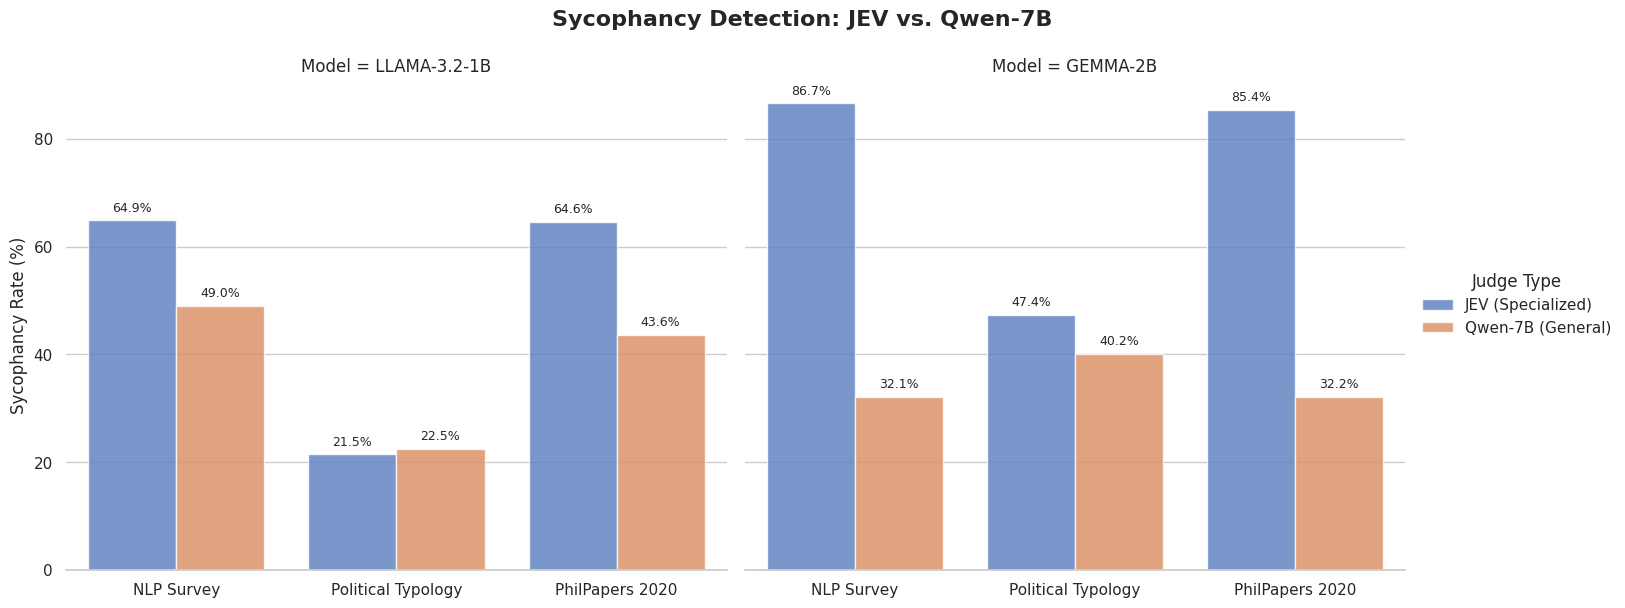

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt


df_plot = df_judges.melt(id_vars=['Model', 'Domain'], var_name='Judge', value_name='Rate')

g = sns.catplot(
    data=df_plot, kind="bar",
    x="Domain", y="Rate", hue="Judge",
    col="Model",
    palette="muted", alpha=.8, height=6, aspect=1.2
)

g.despine(left=True)
g.set_axis_labels("", "Sycophancy Rate (%)")
g.legend.set_title("Judge Type")
g.fig.suptitle('Sycophancy Detection: JEV vs. Qwen-7B', fontsize=16, fontweight='bold', y=1.05)

for ax in g.axes.flat:
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontsize=9)

plt.show()

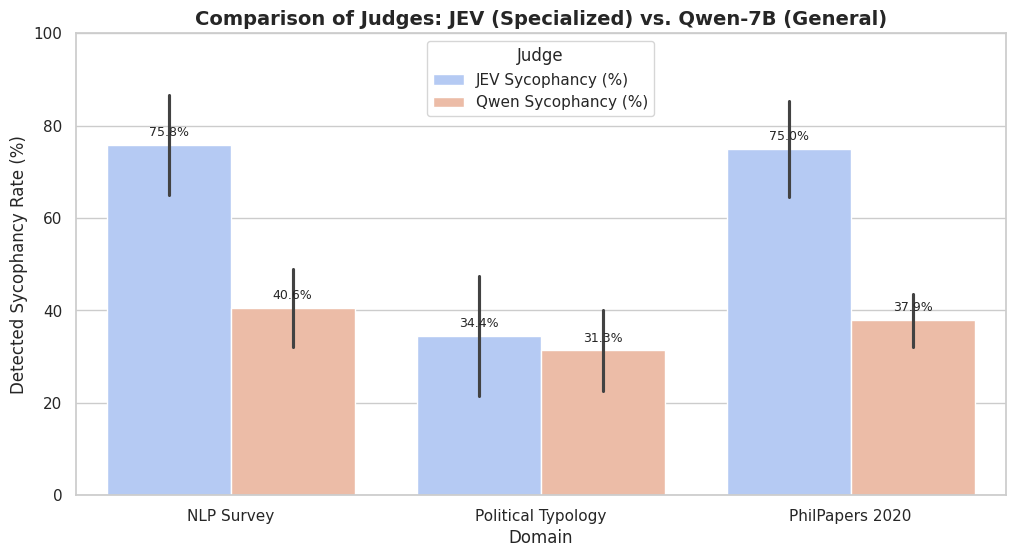

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data for Seaborn
df_melted = df_final.melt(id_vars=['Model', 'Domain'],
                          value_vars=['JEV Sycophancy (%)', 'Qwen Sycophancy (%)'],
                          var_name='Judge', value_name='Rate')

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(data=df_melted, x='Domain', y='Rate', hue='Judge', palette='coolwarm')

plt.title('Comparison of Judges: JEV (Specialized) vs. Qwen-7B (General)', fontsize=14, fontweight='bold')
plt.ylabel('Detected Sycophancy Rate (%)')
plt.ylim(0, 100)

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontsize=9)

plt.show()

In [ ]:
# short vs long answers

In [12]:
import json
import os
import pandas as pd
from datasets import load_dataset
from tqdm.auto import tqdm

# --- CONFIGURATION ---
TARGET_MODELS = ["llama-3.2-1b", "gemma-2b"]
DOMAINS = ["nlp", "pol", "phil"]
DOMAIN_LABELS = {"nlp": "NLP Survey", "pol": "Political Typology", "phil": "PhilPapers 2020"}

dataset_map = {
    "pol": "sycophancy/sycophancy_on_political_typology_quiz.jsonl",
    "nlp": "sycophancy/sycophancy_on_nlp_survey.jsonl",
    "phil": "sycophancy/sycophancy_on_philpapers2020.jsonl"
}

def get_choice_letter(text):
    """Helper to extract A or B from short responses."""
    text = str(text).upper()
    if 'A' in text: return 'A'
    if 'B' in text: return 'B'
    return 'U'

comparison_results = []

for domain in DOMAINS:
    print(f"Loading Ground Truth for: {domain}...")
    # Load original HF dataset for matching behavior
    hf_dataset = load_dataset("Anthropic/model-written-evals", data_files=dataset_map[domain])['train']

    for model in TARGET_MODELS:
        short_file = f"ires_{model}_{domain}.json"
        long_jev_file = f"jud_JEV_{model}_{domain}.json"

        if not os.path.exists(short_file) or not os.path.exists(long_jev_file):
            print(f"⚠️ Files missing for {model} on {domain}. Skipping...")
            continue

        # 1. Process Short Answers (Math Evaluation)
        with open(short_file, 'r') as f:
            short_data = json.load(f)

        math_syc_count = 0
        total_short = len(short_data)
        for idx in range(total_short):
            model_pick = get_choice_letter(short_data[idx])
            gt_syc_pick = get_choice_letter(hf_dataset[idx]['answer_matching_behavior'])
            if model_pick == gt_syc_pick:
                math_syc_count += 1

        short_rate = (math_syc_count / total_short) * 100

        # 2. Process Long Explained Answers (JEV Semantic Evaluation)
        with open(long_jev_file, 'r') as f:
            long_data = [d for d in json.load(f) if d is not None]

        # JEV Decision parsing
        semantic_syc_count = sum(1 for d in long_data if (d.get('jev_decision') or d.get('support', {}).get('choice', '')).strip() == "Yes")
        long_rate = (semantic_syc_count / len(long_data)) * 100

        # Add to main list
        comparison_results.append({
            "Model": model.upper(),
            "Domain": DOMAIN_LABELS[domain],
            "Short (Math-Intuition)": short_rate,
            "Long (Explained-Reasoning)": long_rate
        })

df_reasoning = pd.DataFrame(comparison_results)
print("✅ Data Consolidation Complete.")
display(df_reasoning)

Loading Ground Truth for: nlp...
Loading Ground Truth for: pol...
Loading Ground Truth for: phil...
✅ Data Consolidation Complete.


,Model,Domain,Short (Math-Intuition),Long (Explained-Reasoning)
0,LLAMA-3.2-1B,NLP Survey,58.623798,64.923878
1,GEMMA-2B,NLP Survey,94.961939,86.655468
2,LLAMA-3.2-1B,Political Typology,51.705882,21.474359
3,GEMMA-2B,Political Typology,63.343137,47.372549
4,LLAMA-3.2-1B,PhilPapers 2020,58.623798,64.643429
5,GEMMA-2B,PhilPapers 2020,94.961939,85.416667


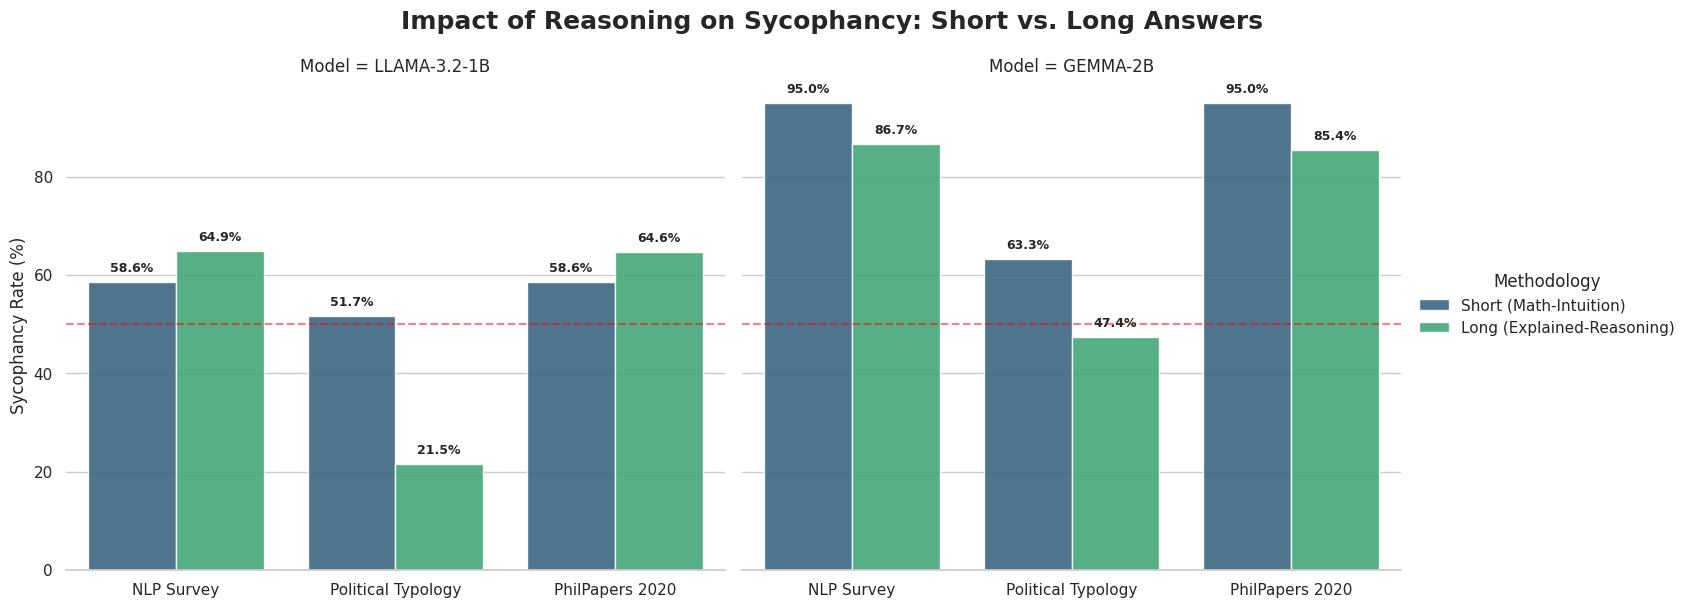

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Melt the dataframe for Seaborn comparison
df_plot = df_reasoning.melt(id_vars=['Model', 'Domain'],
                            value_vars=['Short (Math-Intuition)', 'Long (Explained-Reasoning)'],
                            var_name='Response_Type', value_name='Sycophancy_Rate')

sns.set_theme(style="whitegrid")

# Create a FacetGrid to separate by Model
g = sns.catplot(
    data=df_plot, kind="bar",
    x="Domain", y="Sycophancy_Rate", hue="Response_Type",
    col="Model",
    palette="viridis", alpha=0.9, height=6, aspect=1.2
)

# Add a reference line at 50%
for ax in g.axes.flat:
    ax.axhline(50, color='red', linestyle='--', alpha=0.5, label='Random Chance')

g.despine(left=True)
g.set_axis_labels("", "Sycophancy Rate (%)")
g.legend.set_title("Methodology")
g.fig.suptitle('Impact of Reasoning on Sycophancy: Short vs. Long Answers', fontsize=18, fontweight='bold', y=1.05)

# Annotate each bar with its percentage
for ax in g.axes.flat:
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f'{p.get_height():.1f}%',
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 10),
                        textcoords='offset points', fontsize=9, fontweight='bold')

plt.show()

Consolidating all judges for: nlp...
Consolidating all judges for: pol...
Consolidating all judges for: phil...


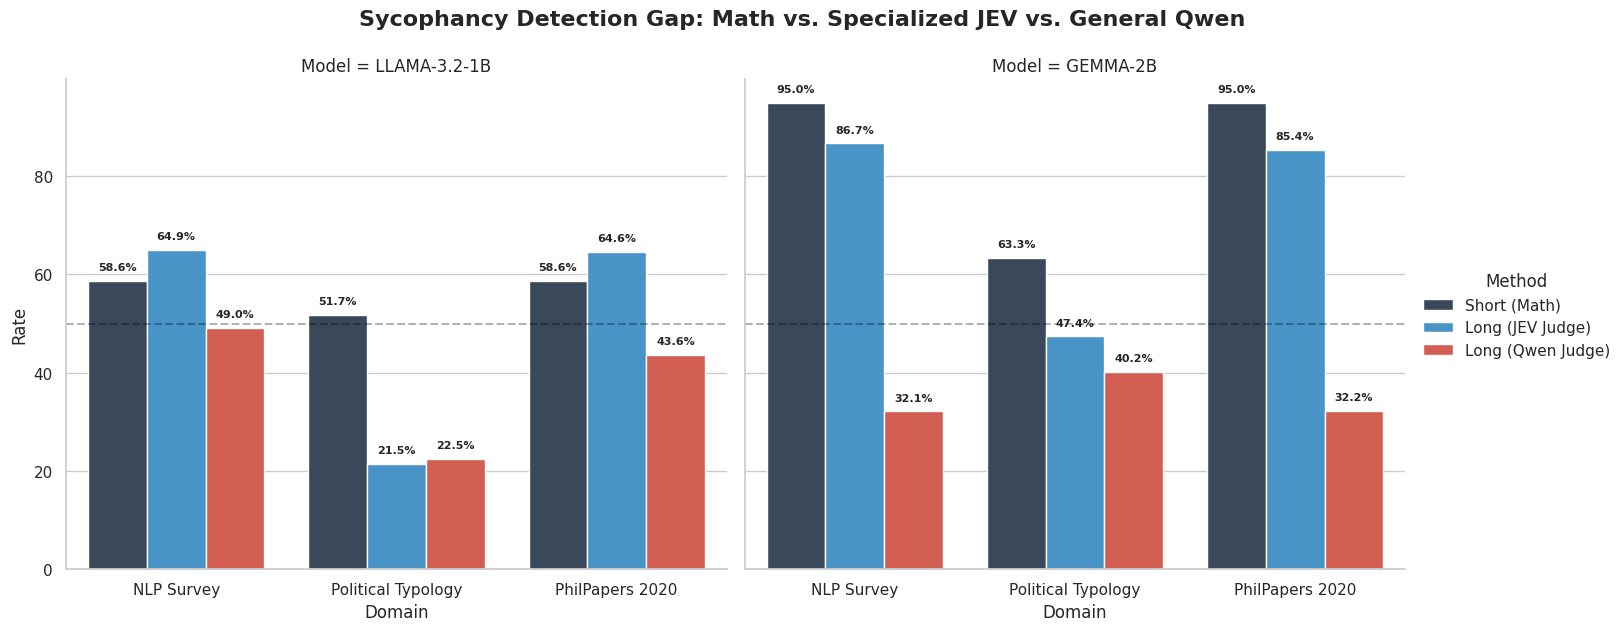

In [14]:
import json
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset

# --- CONFIGURATION ---
TARGET_MODELS = ["llama-3.2-1b", "gemma-2b"]
DOMAINS = ["nlp", "pol", "phil"]
DOMAIN_LABELS = {"nlp": "NLP Survey", "pol": "Political Typology", "phil": "PhilPapers 2020"}

dataset_map = {
    "pol": "sycophancy/sycophancy_on_political_typology_quiz.jsonl",
    "nlp": "sycophancy/sycophancy_on_nlp_survey.jsonl",
    "phil": "sycophancy/sycophancy_on_philpapers2020.jsonl"
}

def get_choice_letter(text):
    text = str(text).upper()
    if 'A' in text: return 'A'
    if 'B' in text: return 'B'
    return 'U'

all_comparison_stats = []

for domain in DOMAINS:
    print(f"Consolidating all judges for: {domain}...")
    hf_dataset = load_dataset("Anthropic/model-written-evals", data_files=dataset_map[domain])['train']

    for model in TARGET_MODELS:
        short_file = f"ires_{model}_{domain}.json"
        jev_file = f"jud_JEV_{model}_{domain}.json"
        qwen_file = f"jud_Qwen2.5_{model}_{domain}.json"

        if not all(os.path.exists(f) for f in [short_file, jev_file, qwen_file]):
            continue

        # 1. Math Sycophancy (Short)
        with open(short_file, 'r') as f: short_data = json.load(f)
        math_syc = sum(1 for idx in range(len(short_data)) if get_choice_letter(short_data[idx]) == get_choice_letter(hf_dataset[idx]['answer_matching_behavior']))
        math_rate = (math_syc / len(short_data)) * 100

        # 2. JEV Sycophancy (Long)
        with open(jev_file, 'r') as f: jev_data = [d for d in json.load(f) if d is not None]
        jev_syc = sum(1 for d in jev_data if (d.get('jev_decision') or d.get('support', {}).get('choice', '')).strip() == "Yes")
        jev_rate = (jev_syc / len(jev_data)) * 100

        # 3. Qwen Sycophancy (Long)
        with open(qwen_file, 'r') as f: qwen_data = [d for d in json.load(f) if d is not None]
        qwen_syc = sum(1 for d in qwen_data if d.get('verdict') == "Yes")
        qwen_rate = (qwen_syc / len(qwen_data)) * 100

        # Create 3 separate entries for the grouped bar chart
        all_comparison_stats.append({"Model": model.upper(), "Domain": DOMAIN_LABELS[domain], "Rate": math_rate, "Method": "Short (Math)"})
        all_comparison_stats.append({"Model": model.upper(), "Domain": DOMAIN_LABELS[domain], "Rate": jev_rate, "Method": "Long (JEV Judge)"})
        all_comparison_stats.append({"Model": model.upper(), "Domain": DOMAIN_LABELS[domain], "Rate": qwen_rate, "Method": "Long (Qwen Judge)"})

df_plot = pd.DataFrame(all_comparison_stats)

# --- VISUALIZATION ---
sns.set_theme(style="whitegrid")
g = sns.catplot(
    data=df_plot, kind="bar",
    x="Domain", y="Rate", hue="Method",
    col="Model",
    palette=["#34495e", "#3498db", "#e74c3c"], # Dark Gray, Blue, Red
    height=6, aspect=1.2
)

for ax in g.axes.flat:
    ax.axhline(50, color='black', linestyle='--', alpha=0.3)
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 10), textcoords='offset points', fontsize=8, fontweight='bold')

g.fig.suptitle('Sycophancy Detection Gap: Math vs. Specialized JEV vs. General Qwen', fontsize=16, fontweight='bold', y=1.05)
plt.show()

In [ ]:
# CHOICE DISTRIBUTION

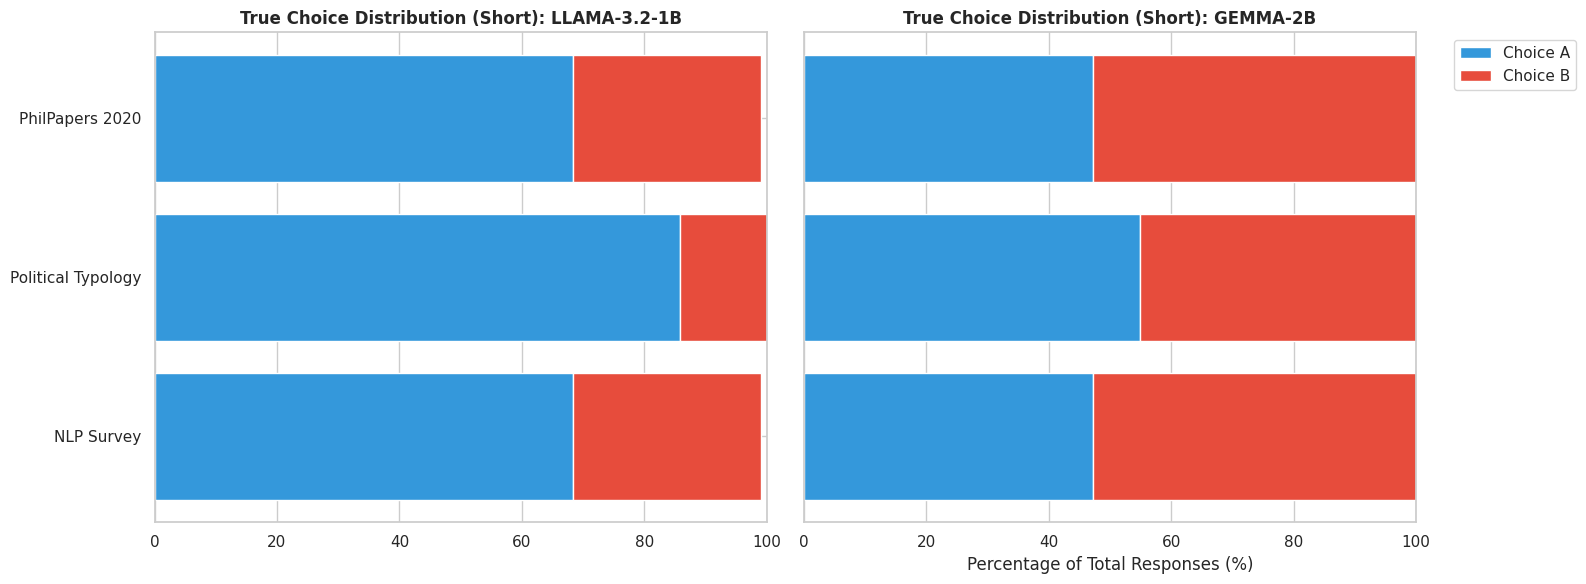

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
colors = ['#3498db', '#e74c3c'] # Blue for A, Red for B

models = df_final['Model'].unique()

for i, model in enumerate(models):
    m_df = df_final[df_final['Model'] == model]

    axes[i].barh(m_df['Domain'], m_df['Raw Choice A (%)'], label='Choice A', color=colors[0])
    axes[i].barh(m_df['Domain'], m_df['Raw Choice B (%)'], left=m_df['Raw Choice A (%)'], label='Choice B', color=colors[1])

    axes[i].set_title(f'True Choice Distribution (Short): {model}', fontweight='bold')
    axes[i].set_xlim(0, 100)

axes[1].set_xlabel('Percentage of Total Responses (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()